# Tome 8, Appendix C: Inversion (Python companion)

Exercises first, solutions at the end. We invert circles and check that they stay circles, test Ptolemy's inequality, build Steiner chains from their closing condition, solve the problem of Apollonius for tangent circles with the complex Descartes theorem, count the curvatures in the integral Apollonian gasket, and classify Möbius maps by their trace. We use `numpy`, `matplotlib` and the standard library.

*Before each solution, predict what the output will look like.*

In [1]:
import cmath, math
import numpy as np
import matplotlib.pyplot as plt
rng = np.random.default_rng(3)
inv = lambda z: 1 / np.conj(z)        # inversion in the unit circle

## Exercises

**P3.1 (★) Circles stay circles.** Sample $200$ points on a random circle not through $0$, invert them, fit a circle to the images by least squares (the equation \eqref{eq:gencircle} is linear in $A,B,C$), and report the residual. Check the distance formula of Proposition 3.2 on random pairs.

**P3.2 (★) Ptolemy.** For $10^5$ random quadruples, compute $\frac{AB\cdot CD+AD\cdot BC}{AC\cdot BD}$ and check that it is at least $1$ (Theorem 3.5). Check equality for random points of a circle in cyclic order.

**P3.3 (★★) Building Steiner chains.** Given $R=1$, $\rho=0.3$ and $n=5,6,8$, compute (if possible) the distance $d$ between the centres from Exercise 3.4, then construct the chain explicitly: find the common inverse points of Lemma 3.7, invert to concentric circles, place the ring, invert back, and check all tangencies.

**P3.4 (★) Apollonius by Descartes.** Take three mutually tangent circles with random radii. Use Theorem 3.10 (curvatures and the complex version for the centres) to find the two circles tangent to all three, and check the tangencies numerically. Then solve Exercise 3.5.

**P3.5 (★★) Curvatures of the integral gasket.** Generate all circles of the gasket $(-1,2,2,3)$ of curvature at most $N=20000$ with the swap rule of Proposition 3.11. How many circles are there? Plot the count of circles with curvature $\le x$ against $x$ on log-log axes and estimate the exponent (theory: the Hausdorff dimension $\delta\approx1.3057$). Which residues modulo $24$ occur, and which integers up to $200$ in those residues are missing?

**P3.6 (★) Möbius maps by trace.** For random matrices of determinant $1$ classify the Möbius map as elliptic, parabolic or loxodromic (Exercise 3.9), and plot the orbit of a point under an elliptic and a loxodromic map. Check the invariance of the cross-ratio (Theorem 3.13).

## Solutions

### P3.1
**How to find it.** With $z=x+iy$, the equation $A|z|^2+2b_1x-2b_2y+C=0$ (where $B=b_1+ib_2$) is linear in $(A,b_1,b_2,C)$; the smallest singular vector of the design matrix gives the best fit.

In [2]:
def fit_circle(z):
    M = np.column_stack([np.abs(z) ** 2, 2 * z.real, -2 * z.imag, np.ones(len(z))])
    _, s, Vt = np.linalg.svd(M)
    A, b1, b2, Cc = Vt[-1]
    B = b1 + 1j * b2
    centre, radius = -np.conj(B) / A, math.sqrt(abs(B) ** 2 - A * Cc) / abs(A)
    return centre, radius, s[-1] / s[0]

c, r = complex(*rng.uniform(-2, 2, 2)), rng.uniform(0.2, 1.0)
z = c + r * np.exp(2j * np.pi * rng.random(200))
w = inv(z)
cw, rw, resid = fit_circle(w)
print("image circle: centre", np.round(cw, 6), "radius", round(rw, 6), " relative residual", resid)
print("predicted:    centre", np.round(c / (abs(c) ** 2 - r * r), 6), "radius", round(r / abs(abs(c) ** 2 - r * r), 6))
P, Q = rng.standard_normal(1000) + 1j * rng.standard_normal(1000), rng.standard_normal(1000) + 1j * rng.standard_normal(1000)
err = np.abs(np.abs(inv(P) - inv(Q)) - np.abs(P - Q) / (np.abs(P) * np.abs(Q))).max()
print("distance formula, max error:", err)

image circle: centre (-0.526499-0.334424j) radius 0.267162  relative residual 9.745404362895799e-17
predicted:    centre (-0.526499-0.334424j) radius 0.267162
distance formula, max error: 7.105427357601002e-15


### P3.2
**How to find it.** Vectorise: draw four arrays of complex numbers.

In [3]:
A, B, Cc, D = (rng.standard_normal(100000) + 1j * rng.standard_normal(100000) for _ in range(4))
ratio = (abs(A - B) * abs(Cc - D) + abs(A - D) * abs(B - Cc)) / (abs(A - Cc) * abs(B - D))
print("smallest ratio for random points:", ratio.min())
t = np.sort(rng.uniform(0, 2 * np.pi, (100000, 4)), axis=1)
A, B, Cc, D = (np.exp(1j * t[:, k]) for k in range(4))
ratio = (abs(A - B) * abs(Cc - D) + abs(A - D) * abs(B - Cc)) / (abs(A - Cc) * abs(B - D))
print("concyclic in cyclic order: ratio - 1 between", (ratio - 1).min(), "and", (ratio - 1).max())

smallest ratio for random points: 1.000000000384181
concyclic in cyclic order: ratio - 1 between -7.771561172376096e-16 and 6.661338147750939e-16


### P3.3
**How to find it.** Follow the proof of Lemma 3.7 literally: $p,q$ are the roots of $x^2-sx+\rho_1^2$; after inverting at $p$, the images are centred at the image of $q$.

n=5: impossible, (R-rho)^2 - 4 R rho tan^2(pi/n) = -0.1434 < 0
n=6: d=0.300000, (b-a)/(b+a)=0.500000, sin(pi/n)=0.500000, worst tangency error 3.6e-15
n=8: d=0.533022, (b-a)/(b+a)=0.382683, sin(pi/n)=0.382683, worst tangency error 3.3e-16


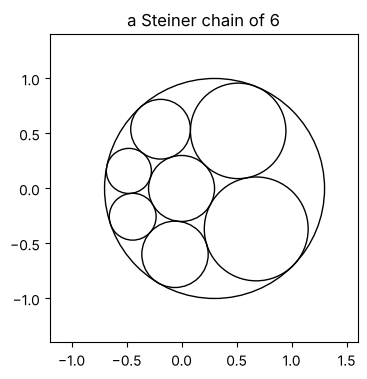

In [4]:
def inv_circle(c, r, O, k2=1.0):
    q = c - O; D = abs(q) ** 2 - r * r
    return O + k2 * q / D, k2 * r / abs(D)

def steiner_chain(Rb, rho, d, n, phase=0.4):
    # inner circle centred at 0 radius rho, outer centred at d radius Rb (inner inside outer)
    s = (rho ** 2 + d ** 2 - Rb ** 2) / d
    p = (s - math.sqrt(s * s - 4 * rho ** 2)) / 2   # one of the two common inverse points
    q = rho ** 2 / p
    (c1, a), (c2, b) = inv_circle(0, rho, p), inv_circle(d, Rb, p)
    assert abs(c1 - c2) < 1e-9                        # concentric images, centred at the image of q
    a, b = min(a, b), max(a, b)
    m, w = (a + b) / 2, (b - a) / 2
    ring = [inv_circle(c1 + m * cmath.exp(1j * (phase + 2 * math.pi * k / n)), w, p) for k in range(n)]
    return ring, (b - a) / (b + a)

for n in (5, 6, 8):
    Rb, rho = 1.0, 0.3
    d2 = (Rb - rho) ** 2 - 4 * Rb * rho * math.tan(math.pi / n) ** 2
    if d2 < 0:
        print(f"n={n}: impossible, (R-rho)^2 - 4 R rho tan^2(pi/n) = {d2:.4f} < 0")
        continue
    d = math.sqrt(d2)
    ring, ratio = steiner_chain(Rb, rho, d, n)
    worst = 0
    for k in range(n):
        (c, r), (c2, r2) = ring[k], ring[(k + 1) % n]
        worst = max(worst, abs(abs(c - c2) - (r + r2)), abs(abs(c) - (rho + r)), abs(abs(c - d) - (Rb - r)))
    print(f"n={n}: d={d:.6f}, (b-a)/(b+a)={ratio:.6f}, sin(pi/n)={math.sin(math.pi / n):.6f}, worst tangency error {worst:.1e}")

ring, _ = steiner_chain(1.0, 0.3, math.sqrt(0.7 ** 2 - 1.2 * math.tan(math.pi / 6) ** 2), 6)
fig, ax = plt.subplots(figsize=(4, 4))
for c, r in [(0, 0.3), (math.sqrt(0.7 ** 2 - 1.2 * math.tan(math.pi / 6) ** 2), 1.0)] + ring:
    ax.add_patch(plt.Circle((c.real if isinstance(c, complex) else c, c.imag if isinstance(c, complex) else 0), r, fill=False))
ax.set_xlim(-1.2, 1.6); ax.set_ylim(-1.4, 1.4); ax.set_aspect("equal"); ax.set_title("a Steiner chain of 6"); plt.show()

For $n=5$ the formula gives $(R-\rho)^2<4R\rho\tan^2\frac\pi5$, so no $d$ exists: with these radii the inner circle is too big for a ring of five (the largest $\rho$ for $n$ circles, attained with concentric circles, is $\frac{1-\sin(\pi/n)}{1+\sin(\pi/n)}$, about $0.26$ for $n=5$). For $n=6$ and $8$ all tangencies hold to rounding error.

### P3.4
**How to find it.** Place the first two circles on the real axis, the third by the cosine law; then $k_4=k_1+k_2+k_3\pm2\sqrt{k_1k_2+k_2k_3+k_3k_1}$, and the complex Descartes theorem gives $k_4c_4$ the same way with products of $k_ic_i$. The sign of the square root for the centres must be chosen to match; we test both.

In [5]:
def apollonius(r1, r2, r3):
    c1, c2 = 0j, complex(r1 + r2, 0)
    a, b, c = r2 + r3, r1 + r3, r1 + r2                 # distances c2c3, c1c3, c1c2
    x = (b * b + c * c - a * a) / (2 * c)
    c3 = complex(x, math.sqrt(b * b - x * x))
    k = [1 / r1, 1 / r2, 1 / r3]; kc = [k[0] * c1, k[1] * c2, k[2] * c3]
    S, e2 = sum(k), k[0] * k[1] + k[1] * k[2] + k[2] * k[0]
    T, f2 = sum(kc), kc[0] * kc[1] + kc[1] * kc[2] + kc[2] * kc[0]
    out = []
    for sg in (1, -1):
        k4 = S + sg * 2 * math.sqrt(e2)
        for sg2 in (1, -1):
            c4 = (T + sg2 * 2 * cmath.sqrt(f2)) / k4
            r4 = 1 / k4
            ok = all(abs(abs(c4 - ci) - (abs(r4) + ri if k4 > 0 else abs(r4) - ri)) < 1e-9 for ci, ri in ((c1, r1), (c2, r2), (c3, r3)))
            if ok: out.append((k4, c4))
    return out

for _ in range(3):
    r = rng.uniform(0.5, 3, 3)
    print(np.round(r, 3), "->", [(round(k4, 6), np.round(c4, 6)) for k4, c4 in apollonius(*r)])
print("Exercise (radii 2, 3, 10):", [round(1 / k4, 6) for k4, _ in apollonius(2, 3, 10)])

[2.355 0.963 1.458] -> [(np.float64(4.552877), np.complex128(2.44756+0.800147j)), (np.float64(-0.254735), np.complex128(0.708029+1.401577j))]
[2.094 1.082 2.419] -> [(np.float64(3.836263), np.complex128(2.176983+0.897086j)), (np.float64(-0.20555), np.complex128(0.543361+2.717299j))]
[2.428 2.024 2.469] -> [(np.float64(2.821506), np.complex128(2.459968+1.299742j)), (np.float64(-0.199555), np.complex128(1.973029+1.667566j))]
Exercise (radii 2, 3, 10): [0.517241, -15.0]


For each sign of the curvature exactly one sign of the second square root gives a circle tangent to all three, as the swap rule predicts. For radii $2,3,10$ the two answers have radii $\frac{15}{29}\approx0.517$ and $-15$ (the enclosing circle).

### P3.5
**How to find it.** Keep a stack of quadruples together with the index of the circle just created; swapping any other index creates a new circle. The curvatures grow, so we prune when a new curvature exceeds $N$.

166022 circles of curvature <= 20000
fitted exponent: 1.3044  (theory 1.3057)


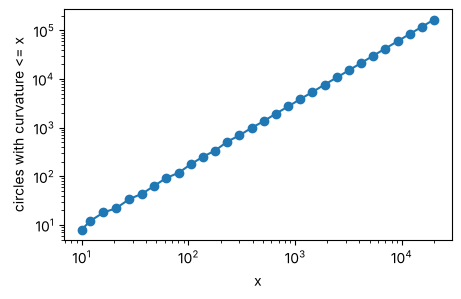

residues mod 24: [2, 3, 6, 11, 14, 15, 18, 23]
integers <= 200 in these residues that do not occur: [78, 159]


In [6]:
N = 20000
root = (-1, 2, 2, 3)
curv = list(root)
stack = [(root, i) for i in range(4)]
# the root's four swaps: the swap of index 3 gives the other circle of curvature 3, which is new
stack = []
for i in range(4):
    q = list(root); q[i] = 2 * (sum(root) - root[i]) - root[i]
    curv.append(q[i]); stack.append((tuple(q), i))
while stack:
    q, last = stack.pop()
    for j in range(4):
        if j == last: continue
        nq = list(q); nq[j] = 2 * (sum(q) - q[j]) - q[j]
        if nq[j] <= N:
            curv.append(nq[j]); stack.append((tuple(nq), j))
curv = np.sort(np.array(curv[1:]))      # drop the outer circle
print(len(curv), "circles of curvature <=", N)
xs = np.unique(np.logspace(1, math.log10(N), 30).astype(int))
counts = np.searchsorted(curv, xs, side="right")
slope = np.polyfit(np.log(xs[10:]), np.log(counts[10:]), 1)[0]
print("fitted exponent:", round(slope, 4), " (theory 1.3057)")
plt.figure(figsize=(5, 3)); plt.loglog(xs, counts, "o-"); plt.xlabel("x"); plt.ylabel("circles with curvature <= x"); plt.show()
res = sorted(set(int(k) % 24 for k in curv))
print("residues mod 24:", res)
present = set(int(k) for k in curv)
missing = [m for m in range(1, 201) if m % 24 in res and m not in present]
print("integers <= 200 in these residues that do not occur:", missing)

The exponent comes out close to $1.3$ (the convergence is slow: Kontorovich and Oh proved that the count is asymptotic to $cN^\delta$). The residues modulo $24$ form a fixed set, eight classes for this gasket: Graham, Lagarias, Mallows, Wilks and Yan proved that every primitive integral gasket misses some classes modulo $24$, and Fuchs showed that $24$ is the right modulus for these local obstructions. Only a few admissible integers are missing here, $78$ and $159$ below $200$. Bourgain and Kontorovich proved that almost all admissible integers occur; Haag, Kertzer, Rickards and Stange showed that in some gaskets infinitely many admissible integers are missed, for reasons related to quadratic reciprocity.

### P3.6
**How to find it.** Normalise to determinant $1$ by dividing by a square root of the determinant; then look at $\mathrm{tr}^2$.

['loxodromic', 'loxodromic', 'loxodromic', 'loxodromic', 'loxodromic'] parabolic


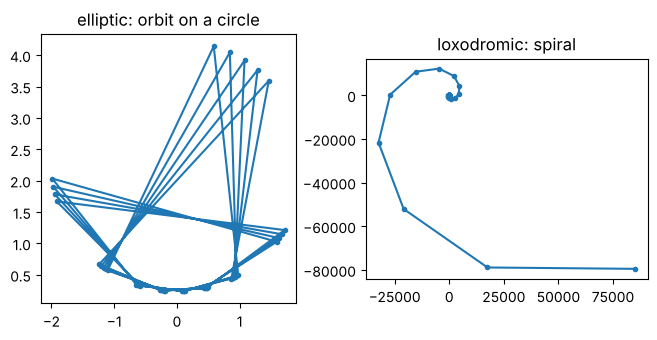

cross-ratio before and after: (0.2614112738-0.2211041692j) (0.2614112738-0.2211041692j)


In [7]:
def kind(M):
    M = M / np.sqrt(np.linalg.det(M))
    t2 = np.trace(M) ** 2
    if abs(t2.imag) < 1e-12 and 0 <= t2.real < 4 - 1e-12: return "elliptic"
    if abs(t2 - 4) < 1e-12: return "parabolic"
    return "loxodromic"
mob = lambda M, z: (M[0, 0] * z + M[0, 1]) / (M[1, 0] * z + M[1, 1])
Ms = [rng.standard_normal((2, 2)) + 1j * rng.standard_normal((2, 2)) for _ in range(5)]
print([kind(M) for M in Ms], kind(np.array([[1, 1], [0, 1]], complex)))
th = 0.7
E = np.array([[math.cos(th), -math.sin(th)], [math.sin(th), math.cos(th)]], complex)   # elliptic, fixes i and -i
Lx = np.array([[1.2 * cmath.exp(0.3j), 0], [0, 1 / (1.2 * cmath.exp(0.3j))]])
fig, ax = plt.subplots(1, 2, figsize=(8, 3.5))
for a, M, z0, ttl in ((ax[0], E, 0.5 + 0.3j, "elliptic: orbit on a circle"), (ax[1], Lx, 0.05 + 0.02j, "loxodromic: spiral")):
    orbit = [z0]
    for _ in range(40): orbit.append(mob(M, orbit[-1]))
    orbit = np.array(orbit); a.plot(orbit.real, orbit.imag, ".-"); a.set_aspect("equal"); a.set_title(ttl)
plt.show()
cr = lambda z1, z2, z3, z4: (z1 - z3) * (z2 - z4) / ((z1 - z4) * (z2 - z3))
z = rng.standard_normal(4) + 1j * rng.standard_normal(4)
print("cross-ratio before and after:", np.round(cr(*z), 10), np.round(cr(*[mob(Ms[0], w) for w in z]), 10))

Random complex matrices give loxodromic maps (the other kinds have probability zero). The elliptic map is the rotation of the Riemann sphere about the axis through $\pm i$; its orbits are circles. The loxodromic map spirals out from its repelling fixed point $0$ towards its attracting fixed point $\infty$.